In [1]:
# Install the packages this notebook needs.
# If they are already installed, this step is quick and harmless.
%pip install -q pandas numpy matplotlib seaborn scipy

Note: you may need to restart the kernel to use updated packages.


# 03. Freedom and health: life expectancy and infant mortality

## Words first

Life expectancy at birth is the average number of years a newborn
would live if death rates at each age stayed as they are in that
year. It is a summary of health conditions, not a prediction for
any one baby.

Infant mortality is the number of babies who die before their
first birthday, per 1,000 live births. Lower is better here, which
is the opposite direction from the other charts. Keep that in
mind when reading the second chart.

Both figures come from the World Bank: life expectancy is
indicator SP.DYN.LE00.IN, and infant mortality is indicator
SP.DYN.IMRT.IN. Both are for 2016 in the main charts, to match
the latest freedom year in this dataset.

In [2]:
import pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 150
plt.rcParams['figure.figsize'] = (10, 6)
ROOT = pathlib.Path('..').resolve()
CHARTS = ROOT / 'charts'
CHARTS.mkdir(exist_ok=True)
DATA = ROOT / 'data' / 'processed'
print('Data folder:', DATA)
print('Charts folder:', CHARTS)

Data folder: /home/hatch/workspace/repo-builds/human-freedom-index/data/processed
Charts folder: /home/hatch/workspace/repo-builds/human-freedom-index/charts


In [3]:
merged = pd.read_csv(DATA / 'freedom_merged.csv')
latest = merged[merged['year'] == 2016].copy()
for outcome in ['life_expectancy_years', 'infant_mortality_per_1000']:
    sub = latest.dropna(subset=[outcome])
    print(outcome, ': countries with data =', len(sub))
    print('  Pearson r with overall freedom:',
          round(sub['hf_score'].corr(sub[outcome]), 3))
    print('  Spearman r with overall freedom:',
          round(sub['hf_score'].corr(sub[outcome], method='spearman'), 3))

life_expectancy_years : countries with data = 161
  Pearson r with overall freedom: 0.621


  Spearman r with overall freedom: 0.662
infant_mortality_per_1000 : countries with data = 160
  Pearson r with overall freedom: -0.579
  Spearman r with overall freedom: -0.703


## Freedom versus life expectancy

Each dot is a country in 2016. Higher on the vertical axis means
longer life expectancy.

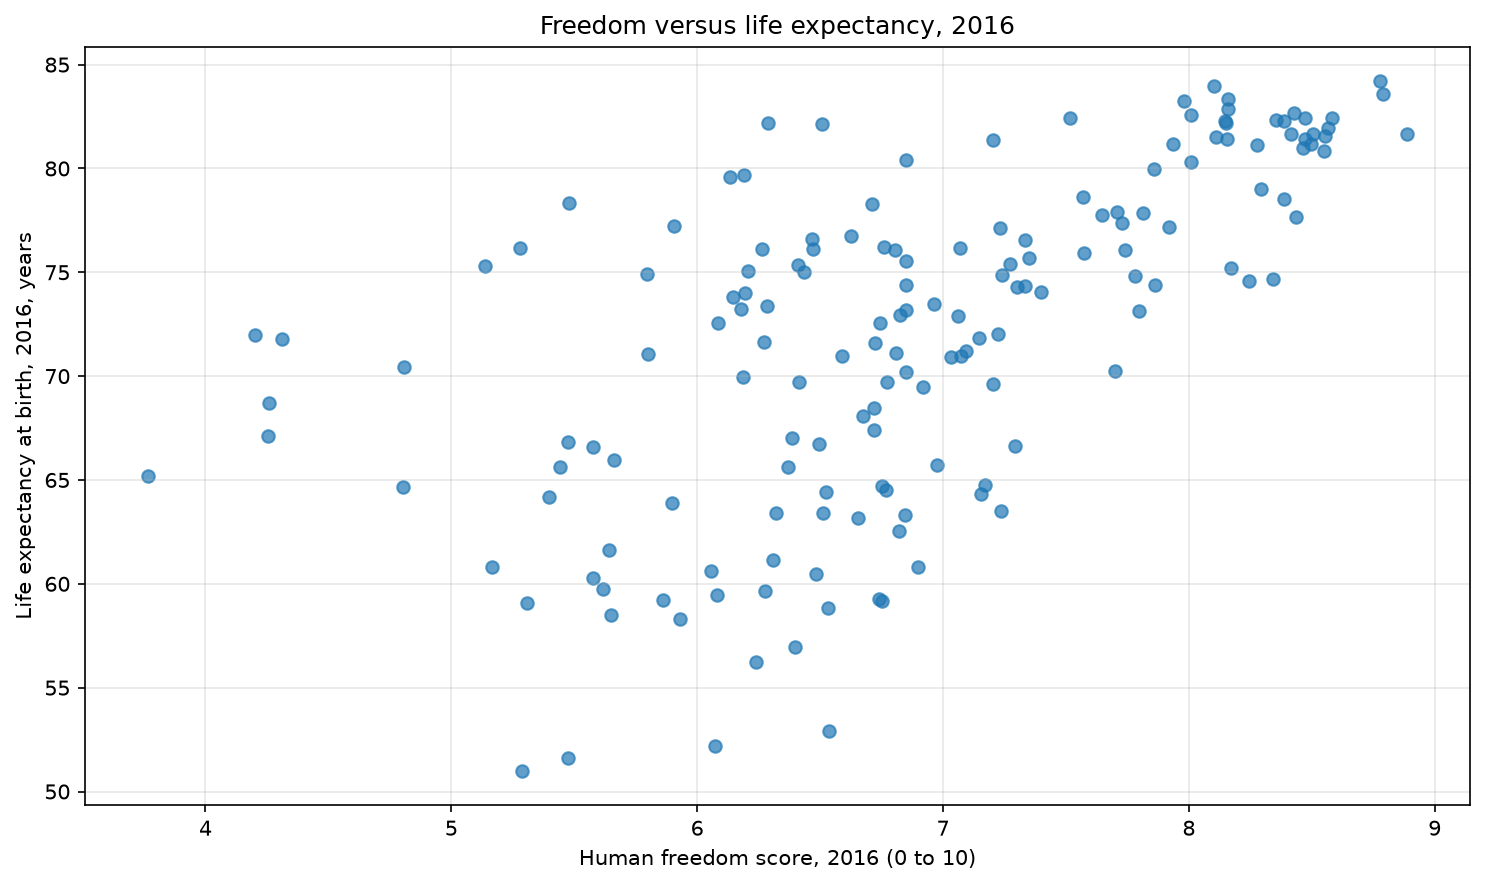

In [4]:
sub = latest.dropna(subset=['life_expectancy_years'])
fig, ax = plt.subplots()
ax.scatter(sub['hf_score'], sub['life_expectancy_years'], alpha=0.7)
ax.set_xlabel('Human freedom score, 2016 (0 to 10)')
ax.set_ylabel('Life expectancy at birth, 2016, years')
ax.set_title('Freedom versus life expectancy, 2016')
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(CHARTS / 'chart_freedom_vs_life.png')
plt.show()

## Freedom versus infant mortality

Each dot is a country in 2016. Lower on the vertical axis means
fewer infant deaths per 1,000 live births. So a downward slope
here points the same way as an upward slope in the life
expectancy chart: higher freedom scores go together with better
health outcomes in this dataset.

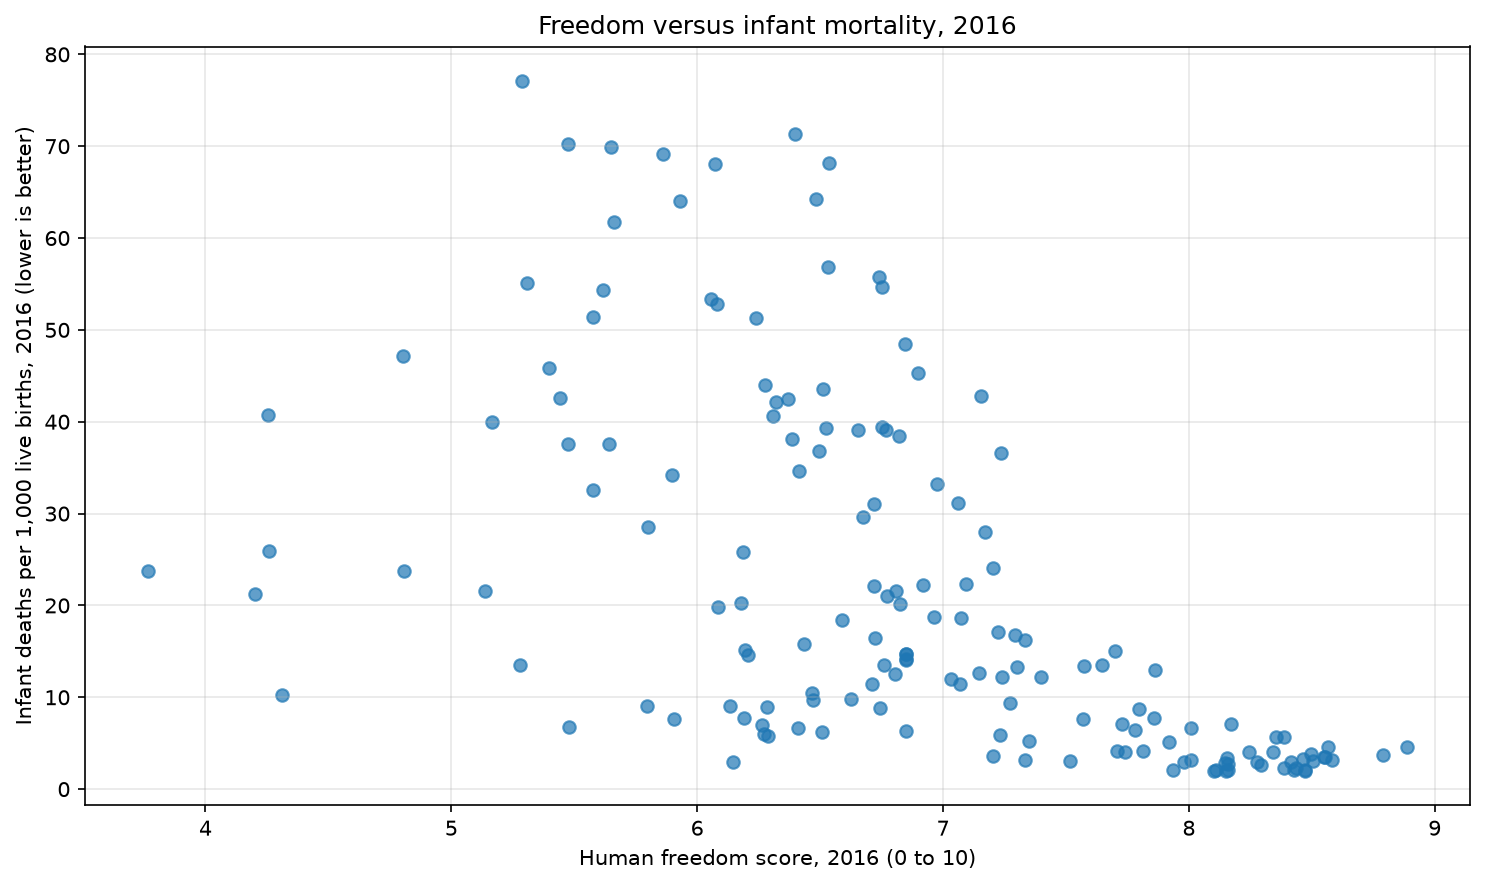

In [5]:
sub2 = latest.dropna(subset=['infant_mortality_per_1000'])
fig, ax = plt.subplots()
ax.scatter(sub2['hf_score'], sub2['infant_mortality_per_1000'], alpha=0.7)
ax.set_xlabel('Human freedom score, 2016 (0 to 10)')
ax.set_ylabel('Infant deaths per 1,000 live births, 2016 (lower is better)')
ax.set_title('Freedom versus infant mortality, 2016')
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(CHARTS / 'chart_freedom_vs_infant.png')
plt.show()

## What to take away, and what not to claim

In 2016, higher freedom scores go together with longer life
expectancy and lower infant mortality in this dataset. That is
again a correlation, not proof of a cause. Health is shaped by
income, nutrition, sanitation, health care, education, and many
other factors. Freedom may be part of that story, but this
notebook alone cannot separate its part from the rest.